# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Scenario.** A fish-export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and (b) how risky its revenue is. The old version modelled stock with Fibonacci numbers and flagged risk when revenue *variance* exceeded 50,000. Here we build a more defensible model and explain why the old one fails.

**How this notebook is organised**

| Part | What we do |
|---|---|
| 0 | Setup |
| 1 | Baseline: Fibonacci "stock" and why it is unrealistic |
| 2 | `FishStock` class (logistic growth with harvesting) |
| 3 | `PriceModel` class (bounded random walk) |
| 4 | Revenue statistics and the coefficient of variation |
| 5 | `RiskAssessor` class (CV rule + Monte Carlo + Value-at-Risk) |
| 6 | Scenario analysis for h = 0.05, 0.10, 0.20, 0.30 |
| 7 | Charts |
| 8 | Extension: closed season over 5 years |

**Reusability.** Every number (r, K, N0, price bounds, thresholds, harvest rate, seed) is a *parameter* of a class or function. To model a different lake or fishery, change the arguments, not the code.

## 0. Setup

We only need three libraries: `numpy` (maths), `pandas` (tables) and `matplotlib` (charts).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (9, 4.5)   # default chart size
pd.options.display.float_format = "{:,.2f}".format

## 1. Baseline: Fibonacci "stock"

The old model used Fibonacci numbers (1, 1, 2, 3, 5, 8, ...) as the fish stock. Each number is the sum of the previous two.

In [2]:
def fibonacci_series(n):
    """Return the first n Fibonacci numbers: 1, 1, 2, 3, 5, ...

    Each new number = previous number + the one before it.
    """
    series = [1, 1]
    while len(series) < n:
        series.append(series[-1] + series[-2])
    return series[:n]


fib_stock = fibonacci_series(15)
print("15 Fibonacci 'stock' values:", fib_stock)

# Growth factor from one step to the next (should settle near 1.618, the golden ratio)
ratios = [fib_stock[i + 1] / fib_stock[i] for i in range(len(fib_stock) - 1)]
print("Last growth factor:", round(ratios[-1], 4))

15 Fibonacci 'stock' values: [1, 1, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144, 233, 377, 610]
Last growth factor: 1.618


### Why unbounded Fibonacci growth is biologically unrealistic

1. **No ceiling.** The stock multiplies by about 1.618 every step forever, but a lake has finite food, oxygen and space, so real stocks level off at a *carrying capacity*.
2. **No harvesting or mortality.** Fibonacci only ever adds. It has no term for fish caught by the cooperative, predators or disease, so it cannot tell us whether fishing is sustainable.
3. **No feedback.** In real populations growth slows as the stock gets crowded and speeds up when it is thin. Fibonacci growth is a fixed rule that ignores the current stock level.
4. **No units or calibration.** The numbers are not tonnes of fish and cannot be matched to data.

## 2. `FishStock`: logistic growth with harvesting

The discrete logistic model with harvesting:

$$N_{t+1} = N_t + r\,N_t\left(1-\frac{N_t}{K}\right) - h\,N_t$$

* $N_t$ = stock in tonnes at week $t$
* $r$ = intrinsic growth rate (0.4), $K$ = carrying capacity (10,000 t)
* $h$ = harvest rate: the fraction of the stock caught each week

**Two facts that help us interpret results later**

* The stock settles at an *equilibrium* $N^* = K\,(1 - h/r)$. If $h \ge r$ the stock collapses to 0.
* Weekly catch at equilibrium is $h N^*$. This is largest when $h = r/2$, giving the **maximum sustainable yield** $MSY = rK/4$.

In [3]:
class FishStock:
    """Fish stock that grows logistically and is harvested every week.

    Parameters
    ----------
    r  : growth rate per week
    K  : carrying capacity (tonnes)
    N0 : starting stock (tonnes)
    h  : harvest rate, fraction of stock caught per week (0 to 1)
    """

    def __init__(self, r=0.4, K=10_000, N0=4_000, h=0.10):
        self.r, self.K, self.N0, self.h = r, K, N0, h

    # ---- theory: quick formulas we can compare simulations against ----
    @property
    def msy(self):
        """Maximum sustainable yield per week (tonnes) = rK/4."""
        return self.r * self.K / 4

    @property
    def equilibrium_stock(self):
        """Stock level the population settles at (tonnes). Zero if h >= r."""
        return max(0.0, self.K * (1 - self.h / self.r))

    @property
    def status(self):
        """Plain-language sustainability label based on h."""
        if self.h >= self.r:
            return "Collapse"                      # catch removes more than growth adds
        if self.h > self.r / 2:
            return "Overfishing"                   # stock survives but yield is below MSY
        return "Sustainable"

    # ---- simulation ----
    def simulate(self, weeks=52, closed_weeks=()):
        """Run the model forward.

        Parameters
        ----------
        weeks        : number of weeks to simulate
        closed_weeks : week-of-year numbers (0-51) with NO harvesting (closed season)

        Returns
        -------
        stock   : array of length weeks+1 (stock at the start of each week, plus the end)
        harvest : array of length weeks (tonnes caught in each week)
        """
        stock = np.zeros(weeks + 1)
        harvest = np.zeros(weeks)
        stock[0] = self.N0

        for t in range(weeks):
            N = stock[t]
            h_now = 0.0 if (t % 52) in closed_weeks else self.h   # closed season => no catch
            harvest[t] = h_now * N
            growth = self.r * N * (1 - N / self.K)
            stock[t + 1] = max(0.0, N + growth - harvest[t])       # stock cannot go negative
        return stock, harvest


# Quick test with h = 0.10
demo = FishStock(h=0.10)
stock, harvest = demo.simulate(52)
print(f"Start: {stock[0]:,.0f} t | After 52 weeks: {stock[-1]:,.0f} t | Equilibrium: {demo.equilibrium_stock:,.0f} t")
print(f"Status: {demo.status} | MSY: {demo.msy:,.0f} t/week")

Start: 4,000 t | After 52 weeks: 7,500 t | Equilibrium: 7,500 t
Status: Sustainable | MSY: 1,000 t/week


## 3. `PriceModel`: bounded random walk

Each week the price moves up or down by a random amount (a *random walk*), starting at UGX 12,000/kg. We clip it to stay between UGX 9,000 and 16,000. A **seed** makes the "random" numbers repeatable.

The method returns many paths at once (a table with one row per path) because Monte Carlo needs thousands of them.

In [4]:
class PriceModel:
    """Weekly fish price (UGX/kg) as a random walk with bounds.

    Parameters
    ----------
    start   : starting price
    low/high: price floor and ceiling
    step_sd : standard deviation of the weekly price change (UGX)
    seed    : random seed so results can be reproduced
    """

    def __init__(self, start=12_000, low=9_000, high=16_000, step_sd=300, seed=42):
        self.start, self.low, self.high, self.step_sd = start, low, high, step_sd
        self.rng = np.random.default_rng(seed)

    def simulate_paths(self, n_paths=1, weeks=52):
        """Return an array of shape (n_paths, weeks) of weekly prices."""
        prices = np.zeros((n_paths, weeks))
        prices[:, 0] = self.start
        for t in range(1, weeks):
            step = self.rng.normal(0, self.step_sd, size=n_paths)          # random weekly change
            prices[:, t] = np.clip(prices[:, t - 1] + step, self.low, self.high)
        return prices


def weekly_revenue(harvest_tonnes, prices):
    """Revenue (UGX) = harvest in kg x price per kg. 1 tonne = 1,000 kg."""
    return harvest_tonnes * 1_000 * prices


# One price path used for the single-run analysis (same path for every harvest rate = fair comparison)
price_path = PriceModel(seed=42).simulate_paths(n_paths=1, weeks=52)[0]
print(f"Price range this year: UGX {price_path.min():,.0f} to {price_path.max():,.0f} per kg")

Price range this year: UGX 10,993 to 13,455 per kg


## 4. Revenue statistics and the coefficient of variation

We use a baseline harvest rate of **h = 0.20** (the rate that gives MSY) to get 52 weekly revenues, then compute the usual statistics.

In [5]:
def revenue_stats(revenue):
    """Return mean, median, variance, standard deviation and CV of a revenue series."""
    mean = revenue.mean()
    std = revenue.std(ddof=1)            # ddof=1 = sample standard deviation
    return {
        "mean (UGX)": mean,
        "median (UGX)": np.median(revenue),
        "variance (UGX^2)": revenue.var(ddof=1),
        "std dev (UGX)": std,
        "CV (no units)": std / mean,     # coefficient of variation = std / mean
    }


base_stock, base_harvest = FishStock(h=0.20).simulate(52)
base_revenue = weekly_revenue(base_harvest, price_path)

stats = revenue_stats(base_revenue)
pd.Series(stats, name="Baseline h=0.20").to_frame()

,Baseline h=0.20
mean (UGX),"11,888,100,820.10"
median (UGX),"11,863,418,110.03"
variance (UGX^2),"838,091,478,690,065,664.00"
std dev (UGX),"915,473,363.18"
CV (no units),0.08


### Why a raw variance threshold of 50,000 is meaningless

**Hint: what are the units of variance?** Revenue is in UGX, so variance is in **UGX squared**. Comparing "UGX²" to the bare number 50,000 mixes units, so the threshold has no real meaning. The demo below shows the second problem: the *same* risk gives a completely different variance depending on the unit we report in.

In [6]:
# Same revenue, reported in UGX vs UGX millions. Risk has not changed, only the unit.
rev_in_millions = base_revenue / 1_000_000

print(f"Variance in UGX^2          : {base_revenue.var(ddof=1):,.0f}")
print(f"Variance in (UGX millions)^2: {rev_in_millions.var(ddof=1):,.0f}")
print(f"CV in UGX                   : {base_revenue.std(ddof=1) / base_revenue.mean():.4f}")
print(f"CV in UGX millions          : {rev_in_millions.std(ddof=1) / rev_in_millions.mean():.4f}")
print("Is variance above 50,000?   ->", base_revenue.var(ddof=1) > 50_000, "(always true at this scale, so it flags everything as risky)")

Variance in UGX^2          : 838,091,478,690,065,664
Variance in (UGX millions)^2: 838,091
CV in UGX                   : 0.0770
CV in UGX millions          : 0.0770
Is variance above 50,000?   -> True (always true at this scale, so it flags everything as risky)


**Conclusion.** Variance depends on the unit and the size of the business, so a fixed cut-off like 50,000 either flags everything or nothing. The **coefficient of variation (CV = standard deviation / mean)** has no units: it says "revenue typically swings by X% of its average", which is comparable across harvest rates, currencies and cooperatives.

## 5. `RiskAssessor`: CV rule, Monte Carlo and Value-at-Risk

**The rule (justified).** CV is a percentage swing, so we classify by it:

| CV | Risk class | Meaning |
|---|---|---|
| below 0.10 | Low | revenue typically moves less than 10% around its average |
| 0.10 to 0.25 | Medium | noticeable swings; plan a cash buffer |
| 0.25 or more | High | swings of a quarter or more; contracts and cash flow are exposed |

These cut-offs are common rule-of-thumb bands, not laws, so they are parameters you can change.

**Monte Carlo.** Price is the random part. We simulate thousands of possible price paths for the year, compute annual revenue for each, and look at the spread.

**Value-at-Risk (VaR, 5%).** The annual revenue level that we expect to fall *below* only 5% of the time (the 5th percentile). Read it as: "in a bad year, revenue could be this low."

In [7]:
class RiskAssessor:
    """Classify revenue risk and estimate Value-at-Risk by Monte Carlo.

    Parameters
    ----------
    low_cv, high_cv : CV cut-offs between Low / Medium / High risk
    var_level       : tail probability for VaR (0.05 = 5%)
    """

    def __init__(self, low_cv=0.10, high_cv=0.25, var_level=0.05):
        self.low_cv, self.high_cv, self.var_level = low_cv, high_cv, var_level

    def classify(self, cv):
        """Turn a coefficient of variation into 'Low', 'Medium' or 'High'."""
        if cv < self.low_cv:
            return "Low"
        if cv < self.high_cv:
            return "Medium"
        return "High"

    def monte_carlo(self, fish, price_model, n_paths=5_000, weeks=52):
        """Simulate annual revenue for many random price paths.

        The stock path is fixed by the harvest rate; only prices are random.
        Returns an array of n_paths annual revenues (UGX).
        """
        _, harvest = fish.simulate(weeks)
        prices = price_model.simulate_paths(n_paths, weeks)          # shape (n_paths, weeks)
        return weekly_revenue(harvest, prices).sum(axis=1)           # add up the weeks

    def value_at_risk(self, annual_revenues):
        """Annual revenue level that is undercut only var_level of the time."""
        return np.percentile(annual_revenues, self.var_level * 100)


assessor = RiskAssessor()
print("CV 0.07 ->", assessor.classify(0.07), "| CV 0.15 ->", assessor.classify(0.15), "| CV 0.30 ->", assessor.classify(0.30))

CV 0.07 -> Low | CV 0.15 -> Medium | CV 0.30 -> High


In [8]:
# Monte Carlo for the baseline (h = 0.20): 5,000 possible years
annual = assessor.monte_carlo(FishStock(h=0.20), PriceModel(seed=1), n_paths=5_000)
var5 = assessor.value_at_risk(annual)

print(f"Mean annual revenue : UGX {annual.mean() / 1e9:,.1f} billion")
print(f"Std dev             : UGX {annual.std(ddof=1) / 1e9:,.1f} billion  (CV = {annual.std(ddof=1) / annual.mean():.3f})")
print(f"5% VaR              : UGX {var5 / 1e9:,.1f} billion  ({1 - var5 / annual.mean():.1%} below the mean)")

Mean annual revenue : UGX 610.7 billion
Std dev             : UGX 58.8 billion  (CV = 0.096)
5% VaR              : UGX 516.0 billion  (15.5% below the mean)


## 6. Scenario analysis

For each harvest rate we report the final stock, total revenue (one price path, the same for all rates), the risk class (CV of weekly revenue), the Monte Carlo 5% VaR, and compare the catch with the theoretical **MSY = rK/4**.

> **Reading the units.** The model's time step is one week, so MSY = rK/4 is in **tonnes per week**. Total revenue is the sum of 52 weeks.

In [9]:
def run_scenarios(harvest_rates, assessor, weeks=52, n_paths=5_000, **fish_kwargs):
    """Run the model for each harvest rate and return a summary table.

    **fish_kwargs lets you change r, K or N0 (e.g. run_scenarios([...], assessor, K=12_000)).
    """
    rows = []
    for h in harvest_rates:
        fish = FishStock(h=h, **fish_kwargs)
        stock, harvest = fish.simulate(weeks)
        revenue = weekly_revenue(harvest, price_path[:weeks])
        cv = revenue.std(ddof=1) / revenue.mean()
        annual = assessor.monte_carlo(fish, PriceModel(seed=1), n_paths, weeks)

        rows.append({
            "h": h,
            "status": fish.status,
            "final stock (t)": stock[-1],
            "equilibrium (t)": fish.equilibrium_stock,
            "avg catch (t/week)": harvest.mean(),
            "% of MSY": 100 * harvest.mean() / fish.msy,
            "total revenue (UGX bn)": revenue.sum() / 1e9,
            "CV": cv,
            "risk class": assessor.classify(cv),
            "5% VaR (UGX bn)": assessor.value_at_risk(annual) / 1e9,
        })
    return pd.DataFrame(rows).set_index("h")


scenarios = run_scenarios([0.05, 0.10, 0.20, 0.30], assessor)
print(f"Theoretical MSY = rK/4 = {FishStock().msy:,.0f} tonnes per week")
scenarios

Theoretical MSY = rK/4 = 1,000 tonnes per week


,status,final stock (t),equilibrium (t),avg catch (t/week),% of MSY,total revenue (UGX bn),CV,risk class,5% VaR (UGX bn)
h,,,,,,,,,
0.05,Sustainable,"8,750.00","8,750.00",417.59,41.76,263.97,0.14,Medium,219.34
0.10,Sustainable,"7,500.00","7,500.00",718.51,71.85,454.20,0.13,Medium,377.71
0.20,Sustainable,"4,999.99","5,000.00",978.30,97.83,618.18,0.08,Low,515.99
0.30,Overfishing,"2,503.72","2,500.00",816.56,81.66,514.41,0.12,Medium,435.61


### What the table tells us

* **h = 0.05 and 0.10 (under-fishing).** The stock grows towards a high equilibrium, but the catch stays well below MSY, so revenue is left on the table.
* **h = 0.20 (the MSY rate, r/2).** Highest total revenue and the catch gets closest to MSY as the stock approaches 5,000 t. The 52-week average is still below MSY because the stock starts at 4,000 t and is still rising.
* **h = 0.30 (overfishing).** The stock is pushed down towards 2,500 t and the equilibrium catch (750 t/week) is *below* MSY, so we earn less while holding a much weaker stock. Beyond h = r = 0.40 the stock would collapse completely.
* **Risk class.** The CV here also includes the *trend* in catch as the stock adjusts, not just price noise, which is why it varies across h. The Monte Carlo VaR isolates the price risk.

**Answer to the cooperative.** (a) Harvesting is sustainable at h up to r/2 = 0.20. At 0.30 the stock survives but is overfished. (b) Revenue risk from prices alone is moderate (annual CV of about 10%), and the 5% VaR shows how far a bad year could fall below average.

## 7. Charts

**(a)** Stock trajectories for each harvest rate on one chart. **(b)** Histogram of simulated annual revenue (baseline h = 0.20) with the 5% VaR marked.

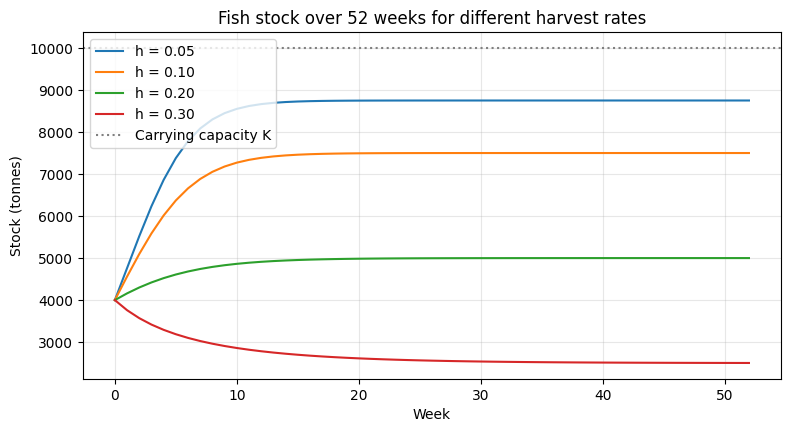

In [10]:
# (a) Stock trajectories
rates = [0.05, 0.10, 0.20, 0.30]
weeks_axis = np.arange(53)

for h in rates:
    stock, _ = FishStock(h=h).simulate(52)
    plt.plot(weeks_axis, stock, label=f"h = {h:.2f}")

plt.axhline(FishStock().K, color="grey", linestyle=":", label="Carrying capacity K")
plt.title("Fish stock over 52 weeks for different harvest rates")
plt.xlabel("Week")
plt.ylabel("Stock (tonnes)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

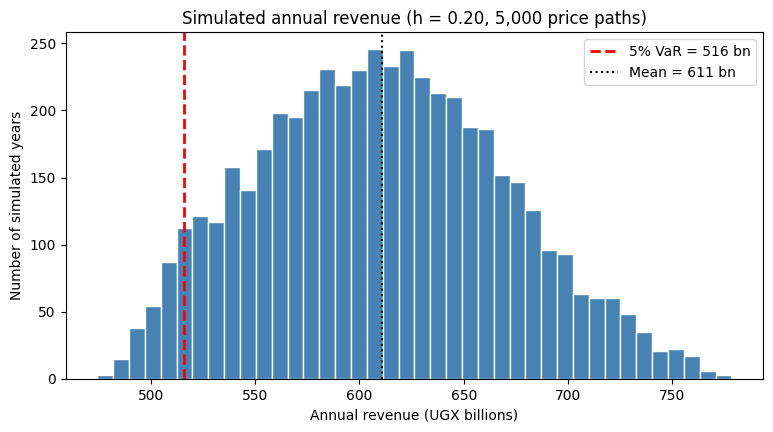

In [11]:
# (b) Histogram of simulated annual revenue with the 5% VaR marked
annual_bn = annual / 1e9                      # UGX billions for readable axis
var5_bn = assessor.value_at_risk(annual) / 1e9

plt.hist(annual_bn, bins=40, color="steelblue", edgecolor="white")
plt.axvline(var5_bn, color="red", linestyle="--", linewidth=2, label=f"5% VaR = {var5_bn:,.0f} bn")
plt.axvline(annual_bn.mean(), color="black", linestyle=":", label=f"Mean = {annual_bn.mean():,.0f} bn")
plt.title("Simulated annual revenue (h = 0.20, 5,000 price paths)")
plt.xlabel("Annual revenue (UGX billions)")
plt.ylabel("Number of simulated years")
plt.legend()
plt.show()

## 8. Extension: closed season over 5 years

**Rule.** No harvesting for 8 weeks each year (we choose weeks 20 to 27, a stand-in for a breeding season; change `CLOSED_WEEKS` to test other windows). We simulate 5 years = 260 weeks and compare long-run revenue with and without the closure, using the same price path for both.

In [12]:
YEARS = 5
WEEKS = 52 * YEARS
CLOSED_WEEKS = tuple(range(20, 28))            # 8 weeks closed every year (week-of-year numbers)

long_prices = PriceModel(seed=7).simulate_paths(1, WEEKS)[0]

rows = []
for h in [0.05, 0.10, 0.20, 0.30]:
    fish = FishStock(h=h)
    for label, closed in [("open all year", ()), ("8-week closure", CLOSED_WEEKS)]:
        stock, harvest = fish.simulate(WEEKS, closed_weeks=closed)
        rows.append({
            "h": h,
            "season": label,
            "5-yr revenue (UGX bn)": weekly_revenue(harvest, long_prices).sum() / 1e9,
            "final stock (t)": stock[-1],
        })

closure = pd.DataFrame(rows)

# Put open vs closed side by side and compute the effect of the closure
table = closure.pivot(index="h", columns="season", values="5-yr revenue (UGX bn)")
table["change (UGX bn)"] = table["8-week closure"] - table["open all year"]
table["change (%)"] = 100 * table["change (UGX bn)"] / table["open all year"]
table

season,8-week closure,open all year,change (UGX bn),change (%)
h,,,,
0.05,936.34,"1,090.45",-154.11,-14.13
0.10,"1,625.84","1,871.02",-245.17,-13.10
0.20,"2,286.21","2,507.30",-221.09,-8.82
0.30,"2,071.01","1,930.38",140.63,7.29


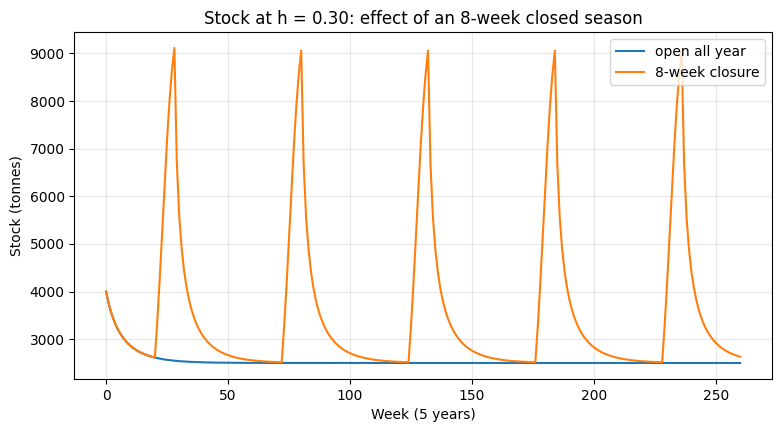

In [13]:
# Visual: stock at h = 0.30 with and without the closure
fish = FishStock(h=0.30)
for label, closed in [("open all year", ()), ("8-week closure", CLOSED_WEEKS)]:
    stock, _ = fish.simulate(WEEKS, closed_weeks=closed)
    plt.plot(stock, label=label)

plt.title("Stock at h = 0.30: effect of an 8-week closed season")
plt.xlabel("Week (5 years)")
plt.ylabel("Stock (tonnes)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Extension findings

* When the cooperative fishes **at or below the MSY rate** (h up to 0.20), the stock is already stable, so closing 8 weeks simply removes 8 weeks of catch and long-run revenue **falls**.
* When it **overfishes (h = 0.30)**, the closure lets the stock recover, and 5-year revenue **rises** even though fishing stops for 8 weeks a year.
* A closed season is therefore a *conservation tool for overfished stocks*, not a free gain. If the cooperative cannot lower h, closing the season is the better option; if h is already near r/2, it is not needed.

## How to reuse this notebook

* **Another fishery or lake:** change `r`, `K`, `N0` in `FishStock(...)` or pass them through `run_scenarios(..., K=..., N0=...)`.
* **Different price behaviour:** change `start`, `low`, `high`, `step_sd` in `PriceModel`.
* **Different risk appetite:** change `low_cv`, `high_cv`, `var_level` in `RiskAssessor`.
* **Move to a script:** copy the class cells (`FishStock`, `PriceModel`, `RiskAssessor`) into `fishmodel.py` and `from fishmodel import *`.

## Findings & Limitations

**Findings.** The logistic model shows that sustainability depends on the harvest rate relative to the growth rate. Harvesting up to h = r/2 = 0.20 is sustainable: the stock settles at 5,000 t, and this rate also earns the most revenue (about UGX 618 billion over 52 weeks). At h = 0.30 the stock survives but is overfished. It falls towards 2,500 t and the equilibrium catch (750 t per week) is below MSY (1,000 t per week), so the cooperative earns less from a weaker stock. Price risk alone is moderate: Monte Carlo annual revenue has a CV of about 10%, and the 5% VaR sits roughly 15% below the mean. The old variance rule failed because variance is measured in UGX squared and changes with the unit, whereas CV does not. A closed season cut 5-year revenue by 9-14% at h of 0.20 or less, but raised it by about 7% at h = 0.30, so it is a remedy for overfishing, not a free gain.

**Limitations.** Stock dynamics are deterministic, so uncertainty from weather, disease and illegal fishing is ignored. The values of r, K, N0 and the price step (UGX 300) are assumed, not estimated from data, and the closed-season weeks are arbitrary. Price is a bounded random walk with no seasonality or exchange-rate effects. The CV risk bands (0.10 and 0.25) are rules of thumb. The single-run tables use one price path, so exact figures change with the seed. Treat all results as illustrative, not as advice for real quota decisions.